### Etapa 2 — Tiempos del ciclo de vida de la orden

Laboratorio: segmentar el tiempo de cada orden desde que se crea hasta que se entrega (o hasta donde llegó, si no se entregó). Lee las tablas de la capa **bronze** (`s3a://olist/bronze/`) y trabaja solo con PySpark (sin pandas).

**Hitos de una orden**

```
compra ──► aprobación ──► entrega al transportista ──► entrega al cliente
(order_purchase_timestamp) (order_approved_at) (order_delivered_carrier_date) (order_delivered_customer_date)

           límite del vendedor (shipping_limit_date, en order_items)
           fecha prometida     (order_estimated_delivery_date)
```

**Etapas (tramos entre hitos)**

| Columna | Desde → hasta | Responsable | Unidad |
|---|---|---|---|
| `horas_aprobacion` | compra → aprobación | Pago (banco / Olist) | horas |
| `dias_preparacion` | aprobación → transportista | Vendedor | días |
| `dias_transito` | transportista → cliente | Transportista | días |
| `dias_lead_time` | compra → cliente | Total | días |
| `dias_despacho_vs_limite` | límite del vendedor → transportista | Vendedor | días (+ = se pasó del límite) |
| `dias_retraso` | fecha prometida → entrega (por fecha, sin hora) | Resultado | días (+ = tarde, − = antes) |
| `dias_prometidos` | compra → fecha prometida | Promesa | días |

**Convenciones**
- Las duraciones se calculan con `unix_timestamp` (segundos) para conservar fracciones; `datediff` redondea a días completos.
- `dias_retraso` positivo = **tarde**. Es el signo contrario a `days_late` del notebook `etapa2_eda`.
- `es_tardio` compara **fechas sin hora**, porque la fecha prometida no trae hora (criterio D1).
- Calidad: los problemas (duraciones negativas, hitos faltantes) se **identifican y cuantifican**, no se corrigen. Las correcciones se deciden en la Etapa 3.

## 1. Setup

In [1]:
import os
from functools import reduce
from pyspark.sql import SparkSession, Window
import pyspark.sql.functions as F

RUSTFS_ENDPOINT = os.environ.get('RUSTFS_ENDPOINT', 'http://rustfs:9000')
S3_KEY  = os.environ.get('AWS_ACCESS_KEY_ID',     'rustfsadmin')
S3_SEC  = os.environ.get('AWS_SECRET_ACCESS_KEY', 'rustfsadmin123')

JARS = ','.join([
    '/opt/spark/extra-jars/iceberg-spark-runtime-4.1_2.13-1.11.0.jar',
    '/opt/spark/extra-jars/hadoop-aws-3.4.2.jar',
    '/opt/spark/extra-jars/aws-sdk-bundle-v2-2.29.52.jar',
])

spark = (
    SparkSession.builder
    .appName('etapa2-eda-tiempos-orden')
    .master('local[*]')
    .config('spark.jars', JARS)
    .config('spark.hadoop.fs.s3a.impl',                   'org.apache.hadoop.fs.s3a.S3AFileSystem')
    .config('spark.hadoop.fs.s3a.endpoint',               RUSTFS_ENDPOINT)
    .config('spark.hadoop.fs.s3a.access.key',             S3_KEY)
    .config('spark.hadoop.fs.s3a.secret.key',             S3_SEC)
    .config('spark.hadoop.fs.s3a.path.style.access',      'true')
    .config('spark.hadoop.fs.s3a.connection.ssl.enabled', 'false')
    .getOrCreate()
)
spark.sparkContext.setLogLevel('ERROR')
print(f'Spark {spark.version} — master: {spark.sparkContext.master}')
print(f'RustFS: {RUSTFS_ENDPOINT}')

26/10/16 08:16:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 4.1.3 — master: local[*]
RustFS: http://rustfs:9000


In [2]:
BRONZE_BASE = 's3a://olist/bronze'
TABLAS = ['orders', 'order_items', 'order_payments', 'customers']

dfs = {t: spark.read.parquet(f'{BRONZE_BASE}/{t}') for t in TABLAS}
orders, order_items, order_payments, customers = (dfs[t] for t in TABLAS)

for nombre, df in dfs.items():
    print(f'{nombre:<16} {df.count():>9,} filas')

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


orders              99,441 filas
order_items        112,650 filas
order_payments     103,886 filas
customers           99,441 filas


In [3]:
def horas(fin, inicio):
    """Diferencia en horas entre dos timestamps (null si falta alguno)."""
    return (F.unix_timestamp(fin) - F.unix_timestamp(inicio)) / 3600

def dias(fin, inicio):
    """Diferencia en días (con decimales) entre dos timestamps."""
    return (F.unix_timestamp(fin) - F.unix_timestamp(inicio)) / 86400

def ver(df, n=30, decimales=2, **kwargs):
    """show() con las columnas numéricas redondeadas, solo para leer mejor."""
    cols = [F.round(c, decimales).alias(c)
            if t in ('double', 'float') or t.startswith('decimal') else F.col(c)
            for c, t in df.dtypes]
    df.select(cols).show(n, truncate=False, **kwargs)

ETAPAS = [
    ('horas_aprobacion',        'Aprobación del pago (horas)'),
    ('dias_preparacion',        'Preparación del vendedor (días)'),
    ('dias_transito',           'Tránsito (días)'),
    ('dias_lead_time',          'Lead time total (días)'),
    ('dias_despacho_vs_limite', 'Despacho vs límite del vendedor (días)'),
    ('dias_retraso',            'Retraso vs fecha prometida (días)'),
]

## 2. Hitos y etapas por orden

Una fila por orden con sus hitos, las duraciones de cada etapa y algunos atributos para segmentar (estado del cliente, tipo de pago, mes).

- `limite_despacho`: el **máximo** `shipping_limit_date` de los ítems de la orden (si hay varios ítems, el vendedor cumple si despacha antes del último límite).
- `tipo_pago`: el método del pago de **mayor monto** (una orden puede tener varios pagos).
- `ultimo_hito`: hasta dónde llegó la orden. `ts_ultimo_hito`: la fecha de ese hito.

In [4]:
# Límite de despacho y número de ítems por orden
por_orden_items = (order_items
    .groupBy('order_id')
    .agg(F.max('shipping_limit_date').alias('limite_despacho'),
         F.count('*').alias('n_items')))

# Tipo de pago principal: el de mayor monto
w_pago = Window.partitionBy('order_id').orderBy(F.col('payment_value').desc(), F.col('payment_sequential'))
pago_principal = (order_payments
    .withColumn('rn', F.row_number().over(w_pago))
    .where(F.col('rn') == 1)
    .select('order_id', F.col('payment_type').alias('tipo_pago')))

In [5]:
tiempos = (orders
    .join(customers.select('customer_id', F.col('customer_state').alias('estado_cliente')), 'customer_id', 'left')
    .join(por_orden_items, 'order_id', 'left')
    .join(pago_principal, 'order_id', 'left')
    .select(
        'order_id', 'order_status', 'estado_cliente', 'tipo_pago', 'n_items',
        F.date_trunc('month', 'order_purchase_timestamp').alias('mes_compra'),
        # Hitos
        F.col('order_purchase_timestamp').alias('ts_compra'),
        F.col('order_approved_at').alias('ts_aprobacion'),
        F.col('order_delivered_carrier_date').alias('ts_despacho'),
        F.col('order_delivered_customer_date').alias('ts_entrega'),
        F.col('order_estimated_delivery_date').alias('fecha_estimada'),
        'limite_despacho',
        # Etapas
        horas('order_approved_at', 'order_purchase_timestamp').alias('horas_aprobacion'),
        dias('order_delivered_carrier_date', 'order_approved_at').alias('dias_preparacion'),
        dias('order_delivered_customer_date', 'order_delivered_carrier_date').alias('dias_transito'),
        dias('order_delivered_customer_date', 'order_purchase_timestamp').alias('dias_lead_time'),
        dias('order_delivered_carrier_date', 'limite_despacho').alias('dias_despacho_vs_limite'),
        F.datediff(F.to_date('order_delivered_customer_date'),
                   F.to_date('order_estimated_delivery_date')).alias('dias_retraso'),
        F.datediff(F.to_date('order_estimated_delivery_date'),
                   F.to_date('order_purchase_timestamp')).alias('dias_prometidos'),
    )
    .withColumn('es_tardio', F.when(F.col('dias_retraso').isNull(), F.lit(None))
                              .otherwise(F.col('dias_retraso') > 0))
    .withColumn('ultimo_hito',
                F.when(F.col('ts_entrega').isNotNull(),    '4_entregada')
                 .when(F.col('ts_despacho').isNotNull(),   '3_en_transportista')
                 .when(F.col('ts_aprobacion').isNotNull(), '2_aprobada')
                 .otherwise('1_compra'))
    .withColumn('ts_ultimo_hito', F.coalesce('ts_entrega', 'ts_despacho', 'ts_aprobacion', 'ts_compra'))
    .cache()
)

print(f'Órdenes: {tiempos.count():,}')
tiempos.printSchema()

Órdenes: 99,441
root
 |-- order_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- estado_cliente: string (nullable = true)
 |-- tipo_pago: string (nullable = true)
 |-- n_items: long (nullable = true)
 |-- mes_compra: timestamp (nullable = true)
 |-- ts_compra: timestamp (nullable = true)
 |-- ts_aprobacion: timestamp (nullable = true)
 |-- ts_despacho: timestamp (nullable = true)
 |-- ts_entrega: timestamp (nullable = true)
 |-- fecha_estimada: timestamp (nullable = true)
 |-- limite_despacho: timestamp (nullable = true)
 |-- horas_aprobacion: double (nullable = true)
 |-- dias_preparacion: double (nullable = true)
 |-- dias_transito: double (nullable = true)
 |-- dias_lead_time: double (nullable = true)
 |-- dias_despacho_vs_limite: double (nullable = true)
 |-- dias_retraso: integer (nullable = true)
 |-- dias_prometidos: integer (nullable = true)
 |-- es_tardio: boolean (nullable = true)
 |-- ultimo_hito: string (nullable = false)
 |-- ts_ultimo_hito: ti

In [6]:
ver(tiempos.select('order_id', 'order_status', 'ultimo_hito', 'horas_aprobacion', 'dias_preparacion',
                   'dias_transito', 'dias_lead_time', 'dias_retraso', 'es_tardio'), n=10)

+--------------------------------+------------+-----------+----------------+----------------+-------------+--------------+------------+---------+
|order_id                        |order_status|ultimo_hito|horas_aprobacion|dias_preparacion|dias_transito|dias_lead_time|dias_retraso|es_tardio|
+--------------------------------+------------+-----------+----------------+----------------+-------------+--------------+------------+---------+
|e481f51cbdc54678b7cc49136f2d6af7|delivered   |4_entregada|0.18            |2.37            |6.06         |8.44          |-8          |false    |
|53cdb2fc8bc7dce0b6741e2150273451|delivered   |4_entregada|30.71           |0.46            |12.04        |13.78         |-6          |false    |
|47770eb9100c2d0c44946d9cf07ec65d|delivered   |4_entregada|0.28            |0.2             |9.18         |9.39          |-18         |false    |
|949d5b44dbf5de918fe9c16f97b45f8a|delivered   |4_entregada|0.3             |3.75            |9.45         |13.21         |-1

## 3. Embudo de hitos

¿Cuántas órdenes alcanzan cada hito? Y, por `order_status`, ¿hasta qué hito llegó cada grupo? Aquí se ve **dónde se "caen"** las órdenes que no terminan, y si el estado declarado es coherente con los hitos registrados (por ejemplo, órdenes `delivered` sin fecha de entrega).

In [7]:
embudo = tiempos.agg(
    F.count('ts_compra').alias('1_compra'),
    F.count('ts_aprobacion').alias('2_aprobada'),
    F.count('ts_despacho').alias('3_en_transportista'),
    F.count('ts_entrega').alias('4_entregada'),
)
total = tiempos.count()
for hito, n in embudo.first().asDict().items():
    print(f'{hito:<20} {n:>8,}  ({n * 100 / total:5.1f} %)')

1_compra               99,441  (100.0 %)
2_aprobada             99,281  ( 99.8 %)
3_en_transportista     97,658  ( 98.2 %)
4_entregada            96,476  ( 97.0 %)


In [8]:
# Filas: estado declarado de la orden; columnas: último hito registrado
(tiempos
    .groupBy('order_status')
    .pivot('ultimo_hito', ['1_compra', '2_aprobada', '3_en_transportista', '4_entregada'])
    .count()
    .na.fill(0)
    .withColumn('total', F.col('1_compra') + F.col('2_aprobada') + F.col('3_en_transportista') + F.col('4_entregada'))
    .orderBy(F.desc('total'))
    .show(truncate=False))

+------------+--------+----------+------------------+-----------+-----+
|order_status|1_compra|2_aprobada|3_en_transportista|4_entregada|total|
+------------+--------+----------+------------------+-----------+-----+
|delivered   |0       |1         |7                 |96470      |96478|
|shipped     |0       |0         |1107              |0          |1107 |
|canceled    |141     |409       |69                |6          |625  |
|unavailable |0       |609       |0                 |0          |609  |
|invoiced    |0       |314       |0                 |0          |314  |
|processing  |0       |301       |0                 |0          |301  |
|created     |5       |0         |0                 |0          |5    |
|approved    |0       |2         |0                 |0          |2    |
+------------+--------+----------+------------------+-----------+-----+



## 4. Órdenes no entregadas: ¿dónde se quedaron y cuánto llevan detenidas?

Para las órdenes sin fecha de entrega se calcula:
- `dias_detenida`: días desde su **último hito** hasta la **fecha de corte** del dataset.
- `dias_desde_compra`: días desde la compra hasta la fecha de corte.
- `promesa_vencida`: si la fecha prometida ya pasó a la fecha de corte.

La **fecha de corte** es el evento más reciente registrado en el dataset (el máximo entre compra, aprobación, despacho y entrega).

Nota: estas órdenes son datos **censurados**: no sabemos cuánto habrían tardado. La técnica formal para este caso es el análisis de supervivencia (Kaplan-Meier), candidato para la Etapa 3.

In [9]:
FECHA_CORTE = tiempos.agg(
    F.max(F.greatest('ts_compra', 'ts_aprobacion', 'ts_despacho', 'ts_entrega'))
).first()[0]
print(f'Fecha de corte del dataset: {FECHA_CORTE}')

no_entregadas = (tiempos
    .where(F.col('ts_entrega').isNull())
    .withColumn('dias_detenida', dias(F.lit(FECHA_CORTE), 'ts_ultimo_hito'))
    .withColumn('dias_desde_compra', dias(F.lit(FECHA_CORTE), 'ts_compra'))
    .withColumn('promesa_vencida', F.col('fecha_estimada') < F.lit(FECHA_CORTE)))
print(f'Órdenes sin fecha de entrega: {no_entregadas.count():,}')

Fecha de corte del dataset: 2018-10-17 17:30:18
Órdenes sin fecha de entrega: 2,965


In [10]:
ver(no_entregadas
    .groupBy('order_status', 'ultimo_hito')
    .agg(F.count('*').alias('ordenes'),
         F.percentile_approx('dias_detenida', 0.5, 10000).alias('dias_detenida_mediana'),
         F.percentile_approx('dias_detenida', 0.9, 10000).alias('dias_detenida_p90'),
         F.round(F.avg(F.col('promesa_vencida').cast('int')) * 100, 1).alias('pct_promesa_vencida'))
    .orderBy(F.desc('ordenes')))

+------------+------------------+-------+---------------------+-----------------+-------------------+
|order_status|ultimo_hito       |ordenes|dias_detenida_mediana|dias_detenida_p90|pct_promesa_vencida|
+------------+------------------+-------+---------------------+-----------------+-------------------+
|shipped     |3_en_transportista|1107   |279.91               |548.18           |100.0              |
|unavailable |2_aprobada        |609    |366.93               |598.05           |100.0              |
|canceled    |2_aprobada        |409    |337.39               |585.78           |100.0              |
|invoiced    |2_aprobada        |314    |335.11               |620.06           |100.0              |
|processing  |2_aprobada        |301    |392.62               |603.82           |100.0              |
|canceled    |1_compra          |141    |71.28                |538.19           |97.2               |
|canceled    |3_en_transportista|69     |252.9                |263.83           |1

In [11]:
# ¿Las no entregadas son recientes (quizá aún en camino) o antiguas (probablemente perdidas o canceladas)?
ver(no_entregadas
    .groupBy('mes_compra')
    .pivot('order_status')
    .count()
    .na.fill(0)
    .orderBy('mes_compra'))

+-------------------+--------+--------+-------+---------+--------+----------+-------+-----------+
|mes_compra         |approved|canceled|created|delivered|invoiced|processing|shipped|unavailable|
+-------------------+--------+--------+-------+---------+--------+----------+-------+-----------+
|2016-09-01 00:00:00|0       |2       |0      |0        |0       |0         |1      |0          |
|2016-10-01 00:00:00|0       |19      |0      |0        |18      |2         |8      |7          |
|2017-01-01 00:00:00|0       |3       |0      |0        |12      |9         |16     |10         |
|2017-02-01 00:00:00|1       |17      |0      |0        |11      |32        |21     |45         |
|2017-03-01 00:00:00|0       |33      |0      |0        |3       |23        |45     |32         |
|2017-04-01 00:00:00|1       |18      |0      |0        |14      |10        |49     |9          |
|2017-05-01 00:00:00|0       |29      |0      |1        |16      |23        |55     |31         |
|2017-06-01 00:00:00

### 4b. ¿Desde qué mes los datos están censurados?

El dataset es una **foto** tomada en la fecha de corte. Para los meses más recientes, los pedidos lentos todavía no habían llegado: solo aparecen como entregados los rápidos. Eso hace que esos meses **parezcan** mejores de lo que fueron (censura por la derecha).

Criterio para considerar un mes **confiable**: que la fecha prometida mediana del mes haya pasado al menos `MARGEN_DIAS` días antes del corte. Se usan 30 días porque, en el análisis anterior (P1f), solo el ~5 % de los pedidos tardíos llegó más de 30 días después de lo prometido: con ese margen, casi todos los pedidos de ese mes ya tuvieron tiempo de llegar o de quedar registrados como tardíos.

In [12]:
MARGEN_DIAS = 30

censura = (tiempos
    .withColumn('dias_promesa_a_corte',
                F.datediff(F.to_date(F.lit(FECHA_CORTE)), F.to_date('fecha_estimada')))
    .groupBy('mes_compra')
    .agg(F.count('*').alias('ordenes'),
         (F.avg(F.col('ts_entrega').isNotNull().cast('int')) * 100).alias('pct_entregadas'),
         (F.avg((F.col('fecha_estimada') < F.lit(FECHA_CORTE)).cast('int')) * 100).alias('pct_promesa_vencida'),
         F.percentile_approx('dias_promesa_a_corte', 0.5, 10000).alias('dias_promesa_a_corte_mediana'),
         (F.avg(F.col('es_tardio').cast('int')) * 100).alias('pct_tardios_entregadas'))
    .withColumn('ventana_confiable', F.col('dias_promesa_a_corte_mediana') >= MARGEN_DIAS)
    .orderBy('mes_compra'))
ver(censura)

confiables = censura.where('ventana_confiable').agg(F.min('mes_compra'), F.max('mes_compra')).first()
print(f'Meses con margen >= {MARGEN_DIAS} días: de {confiables[0]:%Y-%m} a {confiables[1]:%Y-%m}')

+-------------------+-------+--------------+-------------------+----------------------------+----------------------+-----------------+
|mes_compra         |ordenes|pct_entregadas|pct_promesa_vencida|dias_promesa_a_corte_mediana|pct_tardios_entregadas|ventana_confiable|
+-------------------+-------+--------------+-------------------+----------------------------+----------------------+-----------------+
|2016-09-01 00:00:00|4      |25.0          |100.0              |727                         |100.0                 |true             |
|2016-10-01 00:00:00|324    |83.33         |100.0              |686                         |0.74                  |true             |
|2016-12-01 00:00:00|1      |100.0         |100.0              |636                         |0.0                   |true             |
|2017-01-01 00:00:00|800    |93.75         |100.0              |594                         |2.93                  |true             |
|2017-02-01 00:00:00|1780   |92.87         |100.0      

## 5. Distribución de cada etapa

Cuartiles y percentil 90 de cada etapa con `percentile_approx` (algoritmo de percentiles aproximados: no ordena todo el dataset). Esta tabla es la base de los box plots de la sección 8: el gráfico solo necesita estos números, no las 100 mil filas.

Base: órdenes con status `delivered` y fecha de entrega.

In [13]:
entregadas = tiempos.where((F.col('order_status') == 'delivered') & F.col('ts_entrega').isNotNull())
print(f'Órdenes entregadas con fecha: {entregadas.count():,}')

def cuartiles(df, col, grupo=None):
    """Una fila por grupo con n, min, p25, mediana, p75, p90, max y media de una columna."""
    g = [grupo] if grupo else []
    q = F.percentile_approx(col, [0.25, 0.5, 0.75, 0.9], 10000)
    return (df.where(F.col(col).isNotNull())
              .groupBy(*g)
              .agg(F.count(col).alias('n'), F.min(col).alias('min'), q.alias('q'),
                   F.max(col).alias('max'), F.avg(col).alias('media'))
              .select(F.lit(col).alias('etapa'), *g, 'n', 'min',
                      F.col('q')[0].alias('p25'), F.col('q')[1].alias('mediana'),
                      F.col('q')[2].alias('p75'), F.col('q')[3].alias('p90'), 'max', 'media'))

dist_etapas = reduce(lambda a, b: a.unionByName(b), [cuartiles(entregadas, c) for c, _ in ETAPAS])
ver(dist_etapas)

Órdenes entregadas con fecha: 96,470
+-----------------------+-----+--------+-----+-------+-----+-----+------+------+
|etapa                  |n    |min     |p25  |mediana|p75  |p90  |max   |media |
+-----------------------+-----+--------+-----+-------+-----+-----+------+------+
|horas_aprobacion       |96456|0.0     |0.22 |0.34   |14.51|34.59|741.44|10.28 |
|dias_preparacion       |96455|-171.22 |0.87 |1.82   |3.57 |5.99 |125.76|2.8   |
|dias_transito          |96469|-16.1   |4.1  |7.1    |12.03|18.9 |205.19|9.33  |
|dias_lead_time         |96470|0.53    |6.76 |10.22  |15.72|23.09|209.63|12.56 |
|dias_despacho_vs_limite|96469|-1046.86|-5.22|-3.24  |-1.58|-0.11|116.76|-3.35 |
|dias_retraso           |96470|-147.0  |-17.0|-12.0  |-7.0 |-2.0 |188.0 |-11.88|
+-----------------------+-----+--------+-----+-------+-----+-----+------+------+



## 6. Segmentación de los tiempos

Mediana de cada etapa por grupo (solo grupos con al menos 100 órdenes), más el % de tardíos. Para comparar etapas entre grupos se usa la **mediana** (las distribuciones tienen colas largas). En 6a se agregan las **medias**, porque las medias de las etapas suman el lead time medio y permiten repartir los días extra entre etapas.

In [14]:
MIN_N = 100

def medianas_por(df, grupo, min_n=MIN_N):
    aggs = ([F.count('*').alias('ordenes')]
            + [F.percentile_approx(c, 0.5, 10000).alias(c) for c, _ in ETAPAS]
            + [F.percentile_approx('dias_prometidos', 0.5, 10000).alias('dias_prometidos'),
               (F.avg(F.col('es_tardio').cast('int')) * 100).alias('pct_tardios')])
    return df.groupBy(grupo).agg(*aggs).where(F.col('ordenes') >= min_n)

### 6a. Tardío vs a tiempo: ¿qué etapa explica los días extra?

In [15]:
ver(medianas_por(entregadas, 'es_tardio'))

# Medias: suman el lead time medio, así que la diferencia se reparte exactamente entre etapas
medias = (entregadas.groupBy('es_tardio')
          .agg(*[F.avg(c).alias(c) for c in ['dias_preparacion', 'dias_transito', 'dias_lead_time']],
               (F.avg('horas_aprobacion') / 24).alias('dias_aprobacion')))
ver(medias)

+---------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|es_tardio|ordenes|horas_aprobacion|dias_preparacion|dias_transito|dias_lead_time|dias_despacho_vs_limite|dias_retraso|dias_prometidos|pct_tardios|
+---------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|true     |6534   |0.4             |3.05            |26.2         |31.25         |-1.98                  |7           |23             |100.0      |
|false    |89936  |0.34            |1.76            |6.94         |9.81          |-3.33                  |-13         |24             |0.0        |
+---------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+

+---------+----------------+-------------+--------------+---------------+
|es_tardio|dias_preparacion|dias_tran

### 6b. Por tipo de pago

Hipótesis: el **boleto** se paga después de la compra (1 a 3 días hábiles), así que su etapa de aprobación debería ser más larga. ¿Se compensa con una promesa más larga o termina en más tardíos?

In [16]:
ver(medianas_por(entregadas, 'tipo_pago').orderBy(F.desc('horas_aprobacion')))

+-----------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|tipo_pago  |ordenes|horas_aprobacion|dias_preparacion|dias_transito|dias_lead_time|dias_despacho_vs_limite|dias_retraso|dias_prometidos|pct_tardios|
+-----------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|boleto     |19191  |29.06           |1.58            |7.14         |11.34         |-4.3                   |-12         |24             |7.32       |
|debit_card |1483   |0.84            |1.6             |6.13         |8.51          |-2.98                  |-11         |22             |5.33       |
|voucher    |2977   |0.28            |1.85            |7.13         |10.23         |-3.3                   |-13         |24             |6.05       |
|credit_card|72818  |0.27            |1.88            |7.1          |10.01         |-3.09           

### 6c. Por estado del cliente (destino)

In [17]:
ver(medianas_por(entregadas, 'estado_cliente').orderBy(F.desc('dias_transito')))

+--------------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|estado_cliente|ordenes|horas_aprobacion|dias_preparacion|dias_transito|dias_lead_time|dias_despacho_vs_limite|dias_retraso|dias_prometidos|pct_tardios|
+--------------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|AM            |145    |0.32            |1.87            |23.04        |25.88         |-3.4                   |-19         |46             |2.76       |
|AL            |397    |0.33            |2.08            |18.12        |22.33         |-3.09                  |-10         |32             |21.41      |
|PA            |946    |0.41            |1.89            |17.26        |21.07         |-3.18                  |-16         |37             |11.21      |
|MA            |717    |0.61            |1.79            |15.68        |19.19     

### 6d. Por mes de compra

In [18]:
ver(medianas_por(entregadas, 'mes_compra').orderBy('mes_compra'))

+-------------------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|mes_compra         |ordenes|horas_aprobacion|dias_preparacion|dias_transito|dias_lead_time|dias_despacho_vs_limite|dias_retraso|dias_prometidos|pct_tardios|
+-------------------+-------+----------------+----------------+-------------+--------------+-----------------------+------------+---------------+-----------+
|2016-10-01 00:00:00|265    |13.51           |8.87            |3.2          |17.94         |0.0                    |-39         |55             |0.75       |
|2017-01-01 00:00:00|750    |0.29            |1.78            |7.14         |10.72         |-2.25                  |-29         |39             |2.93       |
|2017-02-01 00:00:00|1653   |0.23            |1.87            |7.31         |10.97         |-2.4                   |-20         |31             |2.96       |
|2017-03-01 00:00:00|2546   |0.12            |1.81  

## 7. Calidad de los tiempos (identificar, no corregir)

Duraciones negativas (un hito registrado antes que el anterior) e hitos faltantes según el estado declarado. Se cuantifican aquí; cómo tratarlos se decide en la Etapa 3.

In [19]:
def contar(cond):
    return F.sum(F.when(cond, 1).otherwise(0))

delivered = F.col('order_status') == 'delivered'
calidad = tiempos.agg(
    contar(F.col('horas_aprobacion') < 0).alias('aprobacion_antes_de_compra'),
    contar(F.col('dias_preparacion') < 0).alias('despacho_antes_de_aprobacion'),
    contar(F.col('dias_transito') < 0).alias('entrega_antes_de_despacho'),
    contar(F.col('dias_lead_time') < 0).alias('entrega_antes_de_compra'),
    contar(F.col('dias_prometidos') < 0).alias('promesa_antes_de_compra'),
    contar(delivered & F.col('ts_aprobacion').isNull()).alias('delivered_sin_aprobacion'),
    contar(delivered & F.col('ts_despacho').isNull()).alias('delivered_sin_despacho'),
    contar(delivered & F.col('ts_entrega').isNull()).alias('delivered_sin_entrega'),
    contar(~delivered & F.col('ts_entrega').isNotNull()).alias('con_entrega_pero_otro_status'),
    contar(F.col('n_items').isNull()).alias('ordenes_sin_items'),
)
calidad.show(vertical=True)

-RECORD 0----------------------------
 aprobacion_antes_de_compra   | 0    
 despacho_antes_de_aprobacion | 1359 
 entrega_antes_de_despacho    | 23   
 entrega_antes_de_compra      | 0    
 promesa_antes_de_compra      | 0    
 delivered_sin_aprobacion     | 14   
 delivered_sin_despacho       | 2    
 delivered_sin_entrega        | 8    
 con_entrega_pero_otro_status | 6    
 ordenes_sin_items            | 775  



In [20]:
# Magnitud de la inconsistencia más frecuente: ¿horas (error de registro) o días?
ver(tiempos.where(F.col('dias_preparacion') < 0)
    .select((-F.col('dias_preparacion') * 24).alias('horas_de_desfase'))
    .agg(F.count('*').alias('ordenes'),
         F.percentile_approx('horas_de_desfase', [0.5, 0.9], 10000).alias('mediana_y_p90_horas'),
         F.max('horas_de_desfase').alias('max_horas')))

+-------+--------------------------------------+---------+
|ordenes|mediana_y_p90_horas                   |max_horas|
+-------+--------------------------------------+---------+
|1359   |[17.16777777777778, 51.62222222222223]|4109.26  |
+-------+--------------------------------------+---------+



## 8. Gráficas

Objetivo: mostrar **por qué** describimos los tiempos con **mediana y p90**, y después mostrar los resultados elegidos.

| Gráfica | Archivo | Mensaje |
|---|---|---|
| T0 | `T0_hist_etapas.png` | Distribución de las tres etapas con la campana normal: ninguna es una campana (colas largas y, en la aprobación, dos grupos). Justifica usar mediana y p90 |
| T1 | `T1_hist_transito.png` | (Respaldo) El tránsito en detalle, con la campana normal |
| T2 | `T2_hist_aprobacion_pago.png` | La aprobación por tipo de pago: minutos (casi todo tarjeta) y ~1 día (mayormente boleto) |
| T3 | `T3_box_etapas.png` | Las mismas tres etapas de T0, resumidas en box plots: el tránsito domina |
| T4 | `T4_box_tardio_vs_a_tiempo.png` | La diferencia entre tardíos y a tiempo está en el tránsito |
| T5 | `T5_box_transito_estado.png` | Tránsito por estado con la promesa marcada: lo que decide es el margen |

**Cómo se construyen sin pandas:** Spark agrupa los valores en intervalos (histogramas) o calcula los percentiles (box plots), y a Plotly solo le llegan unas decenas de números.

**Box plots:** caja = p25 a p75, línea dentro = mediana, línea punteada = media, y las **líneas que salen de la caja** (en inglés *whiskers*, "bigotes") van del **p10 al p90**. Se eligen p10 y p90 en lugar de la regla de 1.5 veces la caja para que la línea superior sea justo el p90 que reportamos.

**Archivos:** se guardan en `/home/notebooks/graficos` (en tu Mac: `etapa2/notebooks/graficos/`), con el mismo estilo que las gráficas del EDA general (plantilla `plotly_white`, 900×500, IBM Plex Sans). Para usarlos en las slides, copiarlos a `slides/public/etapa2/` (comando al final de la sección).

Requiere `kaleido` (está en `requirements.txt`; si la imagen de Jupyter es anterior al 15-oct, reconstruirla con `docker compose build jupyter`).

In [35]:
# 8.0 – Estilo, colores y funciones para las gráficas
import math
import plotly.graph_objects as go
from plotly.subplots import make_subplots

FIG_W, FIG_H = 900, 500
TEMPLATE     = 'plotly_white'
FONT_FAMILY  = 'IBM Plex Sans, Arial, sans-serif'
GRAFICOS     = '/home/notebooks/graficos'
os.makedirs(GRAFICOS, exist_ok=True)

# Paleta: un color para los datos, naranja para resaltar, verde para el p90, texto en gris oscuro
AZUL, AZUL_CLARO, NARANJA, VERDE, GRIS, TINTA = '#2a78d6', '#9cc0ec', '#eb6834', '#1baf7a', '#b4b2a9', '#52514e'

def guardar(fig, nombre, width=FIG_W, height=FIG_H):
    """Estilo uniforme (igual que el EDA general), muestra la figura y la guarda como PNG."""
    fig.update_layout(template=TEMPLATE, width=width, height=height, font_family=FONT_FAMILY,
                      font_color=TINTA, margin=dict(l=60, r=40, t=80, b=60))
    fig.show()
    fig.write_image(f'{GRAFICOS}/{nombre}', scale=2)
    print(f'  → {GRAFICOS}/{nombre}')

def resumen(df, col):
    """Media, desviación estándar, mediana, p90 y n de una columna (calculado en Spark)."""
    r = (df.where(F.col(col).isNotNull())
           .agg(F.avg(col).alias('media'), F.stddev(col).alias('desv'), F.count(col).alias('n'),
                F.percentile_approx(col, [0.5, 0.9], 10000).alias('q'))
           .first())
    return {'media': r['media'], 'desv': r['desv'], 'n': r['n'], 'mediana': r['q'][0], 'p90': r['q'][1]}

def histograma(df, col, ancho, minimo, maximo, grupo=None):
    """Cuenta por intervalos de tamaño 'ancho' dentro de [minimo, maximo). Devuelve filas pequeñas (Row)."""
    g = [grupo] if grupo is not None else []
    return (df.where(F.col(col).isNotNull() & (F.col(col) >= minimo) & (F.col(col) < maximo))
              .withColumn('bin', F.floor(F.col(col) / ancho) * ancho)
              .groupBy(*g, 'bin').count()
              .orderBy(*g, 'bin')
              .collect())

def cajas(df, col, grupo=None, escala=1.0):
    """Percentiles p10, p25, p50, p75, p90 y media por grupo, para box plots precalculados."""
    g = [grupo] if grupo is not None else []
    filas = (df.where(F.col(col).isNotNull())
               .groupBy(*g)
               .agg(F.percentile_approx(col, [0.1, 0.25, 0.5, 0.75, 0.9], 10000).alias('q'),
                    F.avg(col).alias('media'), F.count(col).alias('n'))
               .collect())
    salida = {}
    for r in filas:
        clave = r[grupo] if grupo is not None else col
        p10, p25, p50, p75, p90 = (v * escala for v in r['q'])
        salida[clave] = {'p10': p10, 'p25': p25, 'mediana': p50, 'p75': p75, 'p90': p90,
                         'media': r['media'] * escala, 'n': r['n']}
    return salida

def caja(x, s, serie, color, leyenda=True):
    """Una caja precalculada: caja p25–p75, mediana, media (punteada) y bigotes p10–p90."""
    return go.Box(x=[x], q1=[s['p25']], median=[s['mediana']], q3=[s['p75']],
                  lowerfence=[s['p10']], upperfence=[s['p90']], mean=[s['media']],
                  name=serie, legendgroup=serie, showlegend=leyenda,
                  marker_color=color, line_color=color, boxpoints=False)

### T0. Distribución de cada etapa: ¿son una campana?

Histograma de las tres etapas (pedidos entregados), cada una con la **campana normal** que tendría si fuera simétrica (misma media y desviación estándar) y las líneas de **mediana, media y p90**. La aprobación se muestra en **horas** (0 a 72) para que se vean sus dos grupos; las otras dos etapas en días.

Esta gráfica y el box plot de T3 muestran **los mismos datos en dos representaciones**: T0 muestra la forma completa y T3 la resume con percentiles.

horas_aprobacion   media  10.28 | mediana   0.34 | p90  34.59 | desv  20.54 | fuera de rango 2,178 | la campana pondría 30.8 % por debajo de 0
dias_preparacion   media   2.80 | mediana   1.82 | p90   5.99 | desv   3.54 | fuera de rango 1,970 | la campana pondría 21.4 % por debajo de 0
dias_transito      media   9.33 | mediana   7.10 | p90  18.90 | desv   8.76 | fuera de rango 664 | la campana pondría 14.3 % por debajo de 0


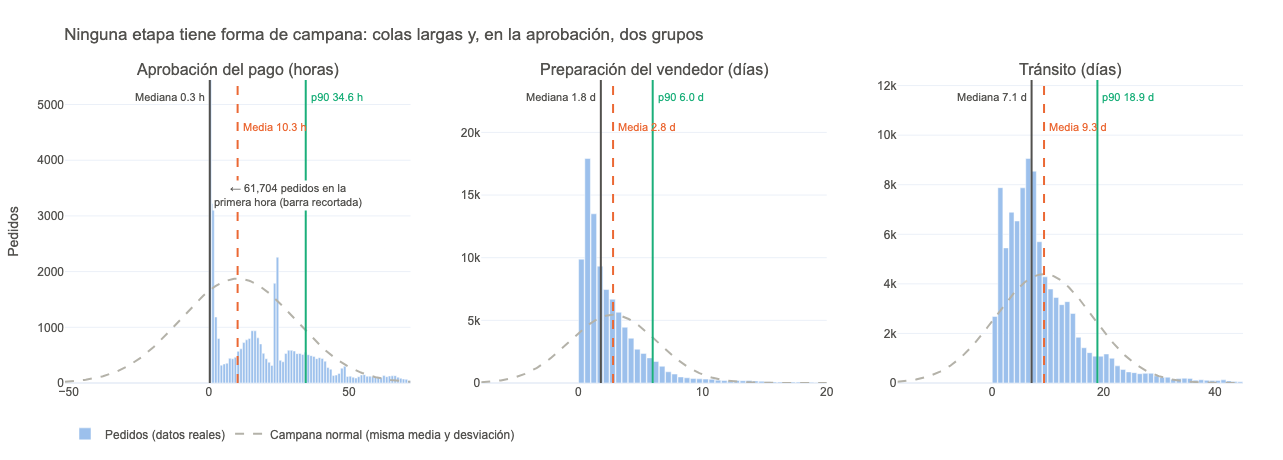

  → /home/notebooks/graficos/T0_hist_etapas.png


In [43]:
# T0 – Histogramas de las tres etapas con la campana normal encimada
PANELES = [
    # columna,            título,                            unidad,  ancho, mínimo, máximo
    ('horas_aprobacion', 'Aprobación del pago (horas)',       'h',     1,     0,      72),
    ('dias_preparacion', 'Preparación del vendedor (días)',   'd',     0.5,   0,      20),
    ('dias_transito',    'Tránsito (días)',                   'd',     1,     0,      45),
]

fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.06, subplot_titles=[p[1] for p in PANELES])
for i, (col, _, unidad, ancho, minimo, maximo) in enumerate(PANELES, start=1):
    r = resumen(entregadas, col)
    barras = histograma(entregadas, col, ancho, minimo, maximo)
    fuera = r['n'] - sum(b['count'] for b in barras)

    # Barras reales
    fig.add_trace(go.Bar(x=[b['bin'] + ancho / 2 for b in barras], y=[b['count'] for b in barras],
                         width=ancho * 0.9, marker_color=AZUL_CLARO, name='Pedidos (datos reales)',
                         legendgroup='datos', showlegend=(i == 1)), row=1, col=i)

    # Campana normal con la misma media y desviación, escalada a pedidos por intervalo
    x_ini = min(r['media'] - 3 * r['desv'], minimo)
    pasos = 300
    xs = [x_ini + (maximo - x_ini) * k / pasos for k in range(pasos + 1)]
    escala = r['n'] * ancho / (r['desv'] * math.sqrt(2 * math.pi))
    ys = [escala * math.exp(-0.5 * ((x - r['media']) / r['desv']) ** 2) for x in xs]
    fig.add_trace(go.Scatter(x=xs, y=ys, mode='lines', line=dict(color=GRIS, width=2, dash='dash'),
                             name='Campana normal (misma media y desviación)',
                             legendgroup='normal', showlegend=(i == 1)), row=1, col=i)

    # Espacio arriba para las etiquetas
    conteos = [b['count'] for b in barras]
    if col == 'horas_aprobacion':
        # La primera hora concentra la mayoría de los pedidos: se recorta esa barra para que se vean
        # el grupo de ~1 día y la campana, y se anota su valor real.
        tope = max(max(conteos[1:]), max(ys)) * 1.25
        fig.add_annotation(x=barras[0]['bin'] + ancho, y=0.62, xref=f'x{i}' if i > 1 else 'x',
                           yref=f'y{i} domain' if i > 1 else 'y domain', xanchor='left', showarrow=False,
                           text=f'← {conteos[0]:,} pedidos en la<br>primera hora (barra recortada)',
                           bgcolor='white', font=dict(color=TINTA, size=11))
    else:
        tope = max(max(conteos), max(ys))
    fig.update_yaxes(range=[0, tope * 1.35], row=1, col=i)
    fig.update_xaxes(range=[x_ini, maximo], row=1, col=i)

    # Líneas de mediana, media y p90 con etiquetas a distintas alturas
    xref = 'x' if i == 1 else f'x{i}'
    yref = 'y domain' if i == 1 else f'y{i} domain'
    for valor, texto, color, dash, y, lado in [
            (r['mediana'], f"Mediana {r['mediana']:.1f} {unidad}", TINTA, 'solid', 0.97, 'right'),
            (r['media'],   f"Media {r['media']:.1f} {unidad}",     NARANJA, 'dash', 0.87, 'left'),
            (r['p90'],     f"p90 {r['p90']:.1f} {unidad}",         VERDE, 'solid', 0.97, 'left')]:
        fig.add_vline(x=valor, line_color=color, line_dash=dash, line_width=2, row=1, col=i)
        fig.add_annotation(x=valor, y=y, xref=xref, yref=yref, text=f' {texto} ', showarrow=False,
                           xanchor=lado, font=dict(color=color, size=11))

    neg = 0.5 * (1 + math.erf((0 - r['media']) / (r['desv'] * math.sqrt(2))))
    print(f"{col:<18} media {r['media']:6.2f} | mediana {r['mediana']:6.2f} | p90 {r['p90']:6.2f} | "
          f"desv {r['desv']:6.2f} | fuera de rango {fuera:,} | la campana pondría {neg * 100:4.1f} % por debajo de 0")

fig.update_yaxes(title_text='Pedidos', row=1, col=1)
fig.update_layout(bargap=0,
                  title='Ninguna etapa tiene forma de campana: colas largas y, en la aprobación, dos grupos',
                  legend=dict(orientation='h', yanchor='top', y=-0.12, x=0))
guardar(fig, 'T0_hist_etapas.png', width=1350, height=460)

### T1. (Respaldo) Distribución del tránsito en detalle

Histograma del tránsito (pedidos entregados) con la **campana normal** que tendrían los datos si fueran simétricos (misma media y desviación estándar). Si los datos fueran normales, media y mediana coincidirían y bastaría con la media.

In [37]:
# T1 – Histograma del tránsito vs la campana normal
ANCHO, MIN_X, MAX_X = 1, 0, 45
r_tr = resumen(entregadas, 'dias_transito')
barras = histograma(entregadas, 'dias_transito', ANCHO, MIN_X, MAX_X)
fuera = r_tr['n'] - sum(b['count'] for b in barras)

# Campana normal con la misma media y desviación, escalada a número de pedidos por intervalo
xs = [x / 4 for x in range(-15 * 4, MAX_X * 4 + 1)]
k = r_tr['n'] * ANCHO / (r_tr['desv'] * math.sqrt(2 * math.pi))
ys = [k * math.exp(-0.5 * ((x - r_tr['media']) / r_tr['desv']) ** 2) for x in xs]

fig = go.Figure()
fig.add_trace(go.Bar(x=[b['bin'] + ANCHO / 2 for b in barras], y=[b['count'] for b in barras],
                     width=ANCHO * 0.9, marker_color=AZUL_CLARO, name='Pedidos (datos reales)'))
fig.add_trace(go.Scatter(x=xs, y=ys, mode='lines', line=dict(color=GRIS, width=2, dash='dash'),
                         name='Campana normal (misma media y desviación)'))
for valor, texto, color, dash, pos in [
        (r_tr['mediana'], f"Mediana {r_tr['mediana']:.1f} d", TINTA, 'solid', 'top left'),
        (r_tr['media'],   f"Media {r_tr['media']:.1f} d",     NARANJA, 'dash', 'top right'),
        (r_tr['p90'],     f"p90 {r_tr['p90']:.1f} d",         VERDE, 'solid', 'top right')]:
    fig.add_vline(x=valor, line_color=color, line_dash=dash, line_width=2,
                  annotation_text=texto, annotation_position=pos, annotation_font_color=color)
fig.update_layout(
    title=dict(text='Tránsito: los datos no son una campana<br>'
                    f'<sup>Pedidos entregados (n={r_tr["n"]:,}). No se muestran {fuera:,} pedidos fuera del rango 0 a {MAX_X} días.</sup>'),
    xaxis_title='Días en tránsito', yaxis_title='Pedidos', bargap=0,
    legend=dict(orientation='h', yanchor='bottom', y=-0.3, x=0))
guardar(fig, 'T1_hist_transito.png')

pct_normal_negativa = 0.5 * (1 + math.erf((0 - r_tr['media']) / (r_tr['desv'] * math.sqrt(2))))
print(f"Media {r_tr['media']:.2f} | mediana {r_tr['mediana']:.2f} | p90 {r_tr['p90']:.2f} | desv {r_tr['desv']:.2f}")
print(f'Una campana normal con esos parámetros pondría el {pct_normal_negativa * 100:.1f} % de los pedidos '
      f'con tránsito NEGATIVO (imposible): la normal no describe estos datos.')

  → /home/notebooks/graficos/T1_hist_transito.png
Media 9.33 | mediana 7.10 | p90 18.90 | desv 8.76
Una campana normal con esos parámetros pondría el 14.3 % de los pedidos con tránsito NEGATIVO (imposible): la normal no describe estos datos.


### T2. Aprobación del pago por tipo de pago

En **escala logarítmica** (cada marca del eje multiplica el tiempo) y separada por tipo de pago. Se ven dos grupos: el de minutos (casi todo tarjeta) y el de ~1 día, que es **mayormente boleto pero también incluye tarjetas** (posiblemente pagos revisados o aprobados al día siguiente). La celda imprime cuántas aprobaciones de ~1 día son de cada tipo.

In [38]:
# T2 – Aprobación del pago por tipo de pago (escala logarítmica)
# Intervalos sobre log10(horas). Valores menores a 0.01 h (36 segundos) se agrupan en la primera barra
# para poder usar escala logarítmica (log de 0 no existe).
aprob = (entregadas
         .where(F.col('horas_aprobacion').isNotNull())
         .withColumn('log_h', F.log10(F.greatest(F.col('horas_aprobacion'), F.lit(0.01))))
         .withColumn('pago', F.when(F.col('tipo_pago') == 'boleto', 'Boleto')
                              .otherwise('Tarjeta, voucher y débito')))
ANCHO_L = 0.1
barras_a = histograma(aprob, 'log_h', ANCHO_L, -2, 3, grupo='pago')
r_ap = resumen(entregadas, 'horas_aprobacion')

fig = go.Figure()
for pago, color in [('Tarjeta, voucher y débito', AZUL), ('Boleto', NARANJA)]:
    b = [r for r in barras_a if r['pago'] == pago]
    fig.add_trace(go.Bar(x=[r['bin'] + ANCHO_L / 2 for r in b], y=[r['count'] for r in b],
                         width=ANCHO_L * 0.9, marker_color=color, opacity=0.75, name=pago))
max_a = max(r['count'] for r in barras_a)
fig.update_yaxes(range=[0, max_a * 1.25], title_text='Pedidos')
marcas = [(1 / 60, '1 min'), (10 / 60, '10 min'), (1, '1 h'), (6, '6 h'), (24, '1 día'), (72, '3 días'), (240, '10 días')]
fig.update_xaxes(tickvals=[math.log10(h) for h, _ in marcas], ticktext=[t for _, t in marcas],
                 title_text='Tiempo de aprobación (escala logarítmica)')
for valor, texto, color, lado in [(r_ap['mediana'], f"Mediana {r_ap['mediana'] * 60:.0f} min", TINTA, 'right'),
                                  (r_ap['p90'], f"p90 {r_ap['p90']:.0f} h", VERDE, 'left')]:
    x = math.log10(max(valor, 0.01))
    fig.add_vline(x=x, line_color=color, line_width=2)
    fig.add_annotation(x=x, y=0.97, xref='x', yref='y domain', text=f' {texto} ', showarrow=False,
                       xanchor=lado, font=dict(color=color, size=12))
# Nota de la primera barra (aprobaciones casi instantáneas agrupadas)
primera = sum(r['count'] for r in barras_a if r['bin'] < -1.95)
fig.add_annotation(x=-2 + ANCHO_L / 2, y=primera, text='≤ 36 s', showarrow=True, arrowhead=0,
                   ax=0, ay=-25, font=dict(color=TINTA, size=11))

fig.update_layout(barmode='overlay', bargap=0,
                  title='Aprobación del pago: dos grupos, minutos y ~1 día (mayormente boleto)',
                  legend=dict(orientation='h', yanchor='bottom', y=1.0, x=0.55))
guardar(fig, 'T2_hist_aprobacion_pago.png')

# Cuántas aprobaciones de ~1 día (entre 12 h y 3 días) son boleto y cuántas son tarjeta u otros
dia = (aprob.where((F.col('horas_aprobacion') >= 12) & (F.col('horas_aprobacion') < 72))
            .groupBy('pago').count().collect())
total_dia = sum(r['count'] for r in dia)
for r in dia:
    print(f"Aprobación entre 12 h y 3 días — {r['pago']}: {r['count']:,} ({r['count'] * 100 / total_dia:.0f} %)")

  → /home/notebooks/graficos/T2_hist_aprobacion_pago.png
Aprobación entre 12 h y 3 días — Boleto: 14,506 (61 %)
Aprobación entre 12 h y 3 días — Tarjeta, voucher y débito: 9,323 (39 %)


### T3. Las tres etapas comparadas (lo que reportamos)

Box plots con los percentiles calculados en Spark. Todo en **días** (la aprobación se convierte de horas a días) para comparar en la misma escala.

In [39]:
# T3 – Box plots de las tres etapas
etapas_box = [('horas_aprobacion', 'Aprobación', 1 / 24), ('dias_preparacion', 'Preparación', 1.0),
              ('dias_transito', 'Tránsito', 1.0)]
fig = go.Figure()
for col, nombre, escala in etapas_box:
    s = cajas(entregadas, col, escala=escala)[col]
    fig.add_trace(caja(nombre, s, nombre, AZUL if nombre == 'Tránsito' else GRIS, leyenda=False))
    if nombre == 'Aprobación':   # en días saldría "0.0 d": se muestra en minutos y horas
        texto = f"mediana {s['mediana'] * 24 * 60:.0f} min · p90 {s['p90'] * 24:.0f} h"
    else:
        texto = f"mediana {s['mediana']:.1f} d · p90 {s['p90']:.1f} d"
    fig.add_annotation(x=nombre, y=s['p90'], text=texto,
                       showarrow=False, yshift=14, font=dict(color=TINTA, size=12))
fig.update_layout(title='¿En qué etapa se va el tiempo?<br>'
                        '<sup>Caja: p25 a p75 · línea dentro: mediana · punteada: media · líneas: p10 a p90</sup>',
                  yaxis_title='Días', showlegend=False)
guardar(fig, 'T3_box_etapas.png')

  → /home/notebooks/graficos/T3_box_etapas.png


### T4. Tardío vs a tiempo, por etapa

In [40]:
# T4 – Box plots agrupados: tardío vs a tiempo en cada etapa
fig = go.Figure()
for col, nombre, escala in etapas_box:
    por_grupo = cajas(entregadas, col, grupo='es_tardio', escala=escala)
    for clave, serie, color in [(False, 'A tiempo', AZUL), (True, 'Tardío', NARANJA)]:
        fig.add_trace(caja(nombre, por_grupo[clave], serie, color, leyenda=(col == 'horas_aprobacion')))
fig.update_layout(boxmode='group', yaxis_title='Días',
                  title='La diferencia entre tardíos y a tiempo está en el tránsito<br>'
                        '<sup>Caja: p25 a p75 · línea dentro: mediana · punteada: media · líneas: p10 a p90</sup>',
                  legend=dict(orientation='h', yanchor='bottom', y=1.02, x=0.7))
guardar(fig, 'T4_box_tardio_vs_a_tiempo.png')

  → /home/notebooks/graficos/T4_box_tardio_vs_a_tiempo.png


### T5. Tránsito por estado del cliente, con la promesa

Cuatro estados que cuentan la historia (los mismos de la slide 2): SP (local), RJ (cercano con problemas), AL (lejano con poco margen) y AM (el más lejano, con mucho margen). La marca negra es la **promesa mediana** (días desde la compra hasta la fecha prometida).

In [41]:
# T5 – Tránsito por estado con la promesa mediana marcada
ESTADOS = ['SP', 'RJ', 'AL', 'AM']
sel = entregadas.where(F.col('estado_cliente').isin(ESTADOS))
trans = cajas(sel, 'dias_transito', grupo='estado_cliente')
promesa = {r['estado_cliente']: r['p'] for r in
           sel.groupBy('estado_cliente').agg(F.percentile_approx('dias_prometidos', 0.5, 10000).alias('p')).collect()}
tardios = {r['estado_cliente']: r['pct'] for r in
           sel.groupBy('estado_cliente').agg((F.avg(F.col('es_tardio').cast('int')) * 100).alias('pct')).collect()}

fig = go.Figure()
for i, e in enumerate(ESTADOS):
    fig.add_trace(caja(e, trans[e], 'Tránsito', AZUL, leyenda=(i == 0)))
fig.add_trace(go.Scatter(x=ESTADOS, y=[promesa[e] for e in ESTADOS], mode='markers',
                         marker=dict(symbol='line-ew', size=40, line=dict(width=3, color=TINTA)),
                         name='Promesa (mediana)'))
for e in ESTADOS:
    fig.add_annotation(x=e, y=promesa[e], text=f'{tardios[e]:.1f} % tardíos', showarrow=False,
                       yshift=16, font=dict(color=NARANJA if tardios[e] > 10 else TINTA, size=12))
fig.update_layout(yaxis_title='Días',
                  title='Lo que decide es el margen entre el tránsito y la promesa<br>'
                        '<sup>Caja: p25 a p75 · línea dentro: mediana · líneas: p10 a p90 · marca negra: días prometidos</sup>',
                  legend=dict(orientation='h', yanchor='bottom', y=1.02, x=0.6))
guardar(fig, 'T5_box_transito_estado.png')

  → /home/notebooks/graficos/T5_box_transito_estado.png


### Copiar las gráficas a las slides

Desde la raíz del repo, en tu Mac (no en el notebook):

```bash
mkdir -p slides/public/etapa2
cp etapa2/notebooks/graficos/T*.png slides/public/etapa2/
```

## 9. Notas

*(Corrida del 2026-10-15 sobre bronze. Laboratorio: son observaciones e hipótesis, no conclusiones finales.)*

**Validación.** 96,470 órdenes `delivered` con fecha de entrega y **6,534 tardíos** (OTD 93.2 %, comparando fechas sin hora): coincide exactamente con el análisis previo hecho en PostgreSQL.

**Fecha de corte y censura.**
- Las duraciones de las órdenes no entregadas se miden contra la **fecha de corte del dataset (2018-10-17)**, nunca contra la fecha actual.
- El periodo útil termina en **agosto de 2018**: septiembre y octubre de 2018 tienen 16 y 4 órdenes, casi todas canceladas.
- Censura (sección 4b): hasta **agosto de 2018** la promesa mediana venció al menos **50 días antes del corte** y el % de pedidos entregados se mantiene en 97–98 %, igual que en el resto de los meses. **La censura solo afecta a septiembre y octubre de 2018** (20 órdenes, ninguna entregada).
- Por eso la baja del lead time desde abril de 2018 (de ~13 a ~7 días) **es real** y no un efecto de la censura; coincide con promesas más cortas (14 días de mediana en agosto).
- Ventana recomendada para comparar meses: **2017-01 a 2018-08** (2016 tiene muy pocos pedidos).

**Embudo.** 99.8 % de las órdenes se aprueba, 98.2 % llega al transportista y 97.0 % se entrega.
- Se cancela en todas las etapas: 141 antes de aprobarse, 409 aprobadas y **69 ya con el transportista**.
- Inconsistencias entre el status y los hitos: **6 `canceled` con fecha de entrega** y **8 `delivered` sin fecha de entrega** (7 se quedaron con el transportista).

**No entregadas (2,965).** Ninguna estaba en curso: casi todas tienen la promesa vencida al corte.
- `shipped`: 1,107 con una mediana de **280 días** detenidas desde el despacho, es decir, paquetes que nunca llegaron.
- `processing`, `invoiced` y `unavailable`: alrededor de **un año** detenidas; estados abandonados.
- Las `shipped` que nunca llegaron se disparan en **marzo (133) y abril (99) de 2018**, la misma época de la crisis de transporte: ese episodio produjo retrasos **y** pérdidas.

**Distribución de las etapas (entregadas).**

| Etapa | Mediana | p90 |
|---|---:|---:|
| Aprobación | 0.34 h (~20 min) | 34.6 h |
| Preparación (vendedor) | 1.8 días | 6.0 días |
| Tránsito | **7.1 días** | 18.9 días |
| Lead time | 10.2 días | 23.1 días |

- La aprobación tiene dos grupos: casi inmediata o de más de un día (ver tipo de pago).
- Los vendedores despachan en mediana **3.2 días antes** de su límite.

**Tardío vs a tiempo.** Los tardíos tardan en promedio **22.9 días más**: **+19.9 de tránsito (87 %)**, +2.9 de preparación (13 %) y casi nada de aprobación. La promesa es casi igual (23 vs 24 días): no llegan tarde por prometerles menos, sino por el **transporte**.

**Tipo de pago (hipótesis del boleto: confirmada en lo descriptivo).**
- El **boleto** tarda **29 horas** en aprobarse (mediana) contra ~0.3 horas con tarjeta.
- La promesa **no lo compensa** (24 días igual que la tarjeta), y tiene más tardíos: **7.3 %** contra 6.7 % (crédito), 6.1 % (voucher) y 5.3 % (débito).
- Curioso: con boleto el vendedor prepara más rápido (1.58 vs 1.88 días) y despacha con más margen. Hipótesis: el límite de despacho se cuenta desde la compra, no desde la aprobación.
- Pendiente: probar si la diferencia de tardíos es estadísticamente significativa y si se mantiene dentro de cada estado.

**Por estado del cliente.**
- La preparación es casi igual en todo el país (~1.8 días).
- Lo que cambia es el **tránsito**: de 4.4 días (SP) a 23 días (AM), y la **promesa**: de 19 días (SP) a 46 (AM).
- Los estados con más tardíos: AL 21 %, MA 17 %, SE 15 %.

**Por mes.**
- **Black Friday (nov 2017):** subieron la preparación (2.0 → 2.7 días) y el tránsito (7.1 → 8.8): se saturaron vendedores y transporte.
- **Feb–mar 2018:** tránsito de 11.0 y 9.9 días con preparación normal; 14 % y **19 %** de tardíos: problema de transporte.

**Calidad (identificada, no corregida).**

| Inconsistencia | Órdenes |
|---|---:|
| Despachadas antes de ser aprobadas | 1,359 (mediana 17 h de desfase; máximo 171 días) |
| Entregadas antes del despacho | 23 |
| `delivered` sin aprobación / sin despacho / sin entrega | 14 / 2 / 8 |
| Con fecha de entrega pero otro status | 6 |
| Sin ítems | 775 |
| Despacho vs límite con valores extremos (mínimo −1,046 días) | a revisar en `shipping_limit_date` |

**Para la Etapa 3.**
- Definir la ventana de análisis (2017-01 a 2018-08) y cómo tratar los meses censurados.
- Decidir el tratamiento de cada inconsistencia de la tabla anterior.
- Si se modela el tiempo de entrega: análisis de supervivencia para incluir las órdenes no entregadas.
- Variables candidatas que salen de aquí: tipo de pago, estado del cliente y promesa (holgura).

### Al terminar de explorar, liberar recursos:
# tiempos.unpersist()
# spark.stop()